# 09 — Image model: the six-epoch B0 pilot

**Version 2 reporting boundary.** Primary ranking is unweighted mean outer-fold **ROC-AUC**; AP is secondary. An inner-validation pilot or uncertainty experiment has no five-fold estimate, so its ROC-AUC is explicitly exploratory. The saved image recipes, AP-selected checkpoints/epochs and AP-based admission gates remain unchanged and are labelled historical selection rules. This is a presentation migration, not a ROC-selected image refit. Executing every cell reads saved artifacts and writes only new v2 reports: no image smoke, checkpoint inference, training, calibration fitting, cutoff selection, final all-development fit or reserved-test access occurs. The added metadata experiment uses its own explicit v2 ROC selection identity.

Can an image model rank melanoma images above benign images? EfficientNet-B0
(B0) is a convolutional neural network: it learns image patterns such as edges,
texture and colour. Its starting weights were learned on ImageNet, a large
general-image dataset, before being adapted to this task.

Four training **recipes** (learning rate and class weighting) were compared.
An **epoch** is one pass through the fitting data; a **checkpoint** stores the
model's learned weights at an epoch. We report each recipe's saved checkpoint
with the highest validation average precision (AP).

This is an **inner-validation pilot**: patients held out from fitting guide early
choices. Because those same labels helped choose recipes and epochs, these are
exploratory results. Full out-of-fold (OOF) evaluation would test the complete
selection process on independent outer folds; the reserved test comes last.
Outer fold 0 and the reserved test are excluded here.

This notebook reads saved results without training or fitting calibration.
Original outputs are preserved; new reports use the separate v2 presentation namespace.
Continue with [architecture comparison](10_image_architecture_comparison.ipynb).


## Setup and verification

Use the project's `.venv` environment. The checks below verify saved source,
settings, files and patient memberships, then independently recompute the
reported metrics. File hashes act as fingerprints: a changed file fails the
check. This protects the meaning of the historical results after code changes.
No reserved-test files are loaded.


In [2]:
import json
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "src/melanoma_detection").is_dir() and (path / "configs/image_model.yaml").is_file())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from melanoma_detection.image_evaluation import load_historical_pilot, metric_table, curve_tables, sha256
from melanoma_detection.image_reporting import (plot_learning_curves, plot_training_losses,
    plot_roc_precision_recall, plot_confusion_matrices, plot_reliability_checks,
    save_figure)
from melanoma_detection.metadata_evaluation import probability_metrics
pilot = load_historical_pilot(PROJECT_ROOT)
from melanoma_detection.image_roc_reporting import report_directory, show_saved_figure, save_figure
run_dir = pilot["run_dir"]
report_dir = report_directory(PROJECT_ROOT, "original", '09_image_b0_pilot')
figures_dir, tables_dir = report_dir / "figures", report_dir / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)
config = pilot["manifest"]["compatibility"]["config"]
summary, history, predictions = pilot["summary"], pilot["histories"], pilot["predictions"]
epochs = dict(zip(pilot["records"].pipeline_id, pilot["records"].best_epoch))
plt.rcParams.update({"font.size": 10, "figure.facecolor": "white", "axes.facecolor": "white"})
print("Historical run:", summary["status"], "| saved compatibility:", pilot["manifest"]["compatibility_sha256"])
display(pd.DataFrame([pilot["verification"]]))
display(pd.DataFrame([pilot["manifest"]["compatibility"]["runtime"]["packages"]]))


Historical run: complete | saved compatibility: e8b08f551f3785c74ace53f5b5dc5d282f146de04bdbd7a1df82a48277ed4fbc


,archive_verified,artifacts_verified,checkpoints_verified,images_verified,reserved_test_loaded
0,True,True,True,True,False


,torch,torchvision,numpy,pandas,scikit-learn,Pillow,PyYAML
0,2.14.0+cu130,0.29.0+cu130,2.5.2,3.0.5,1.9.0,12.3.0,6.0.3


## Patients and image preparation

Keep all images from one patient in the same partition, so a model cannot learn
from a patient it later evaluates. The table distinguishes **fitting** patients,
**inner-validation** patients, and **outer-excluded** patients whose labels are
not used here.

Only RGB images enter the model. Each whole image is resized to 224 × 224 pixels
using bilinear interpolation. ImageNet normalisation rescales colour channels
to the range expected by the pretrained network. During fitting, weak random
flips and rotations add **augmentation**: varied views intended to discourage
memorising an image's orientation. Validation uses the same preparation every
time, without random augmentation.


In [3]:
partitions = {"fitting": pilot["fitting"], "inner_validation": pilot["validation"],
    "outer_excluded": pilot["outer_excluded"]}
display(pd.DataFrame([{"partition": name, "images": len(frame),
    "patients": frame.patient_id.nunique(), "melanoma_images":
    int(frame.target.sum()) if name != "outer_excluded" else np.nan}
    for name, frame in partitions.items()]).style.format(na_rep="Not used"))
audit = pilot["image_audit"]
print("Audited images:", audit["images"], "| within-patient duplicate groups:",
    len(audit["duplicate_groups_within_patient"]), "| label conflicts:", audit["label_conflicts"])
print("Patient overlap: 0 | outer predictions: none | reserved test loaded: False")
display(pd.DataFrame(config["candidates"]["pilot_recipes"]))
display(pd.DataFrame([config["training"]]))


,partition,images,patients,melanoma_images
0,fitting,3660,225,70.000000
1,inner_validation,1834,113,33.000000
2,outer_excluded,1370,84,Not used


Audited images: 6864 | within-patient duplicate groups: 158 | label conflicts: 0
Patient overlap: 0 | outer predictions: none | reserved test loaded: False


,id,backbone_lr,loss_weight
0,lr3e5_none,0.00003,none
1,lr1e4_none,0.00010,none
2,lr3e5_sqrt,0.00003,sqrt_ratio
3,lr1e4_sqrt,0.00010,sqrt_ratio


,microbatch,effective_batch,min_microbatch,head_lr,weight_decay,warmup_epochs,schedule_epochs,min_lr_factor,gradient_clip,amp,num_workers,seed
0,64,64,4,0.001,0.0001,1,30,0.1,1.0,True,0,42


**Read the preview:** each row is one fitting image; the left column is the
original and the next three columns are seeded weak variants. `target=1` means
melanoma and `target=0` benign. Compare lesion edges, texture and colour across
the row. Rotation can create black corners or remove peripheral pixels; an
intact centre alone does not prove that the whole lesion is preserved. This
deliberate label mix is a quality check, not a representative prevalence sample.


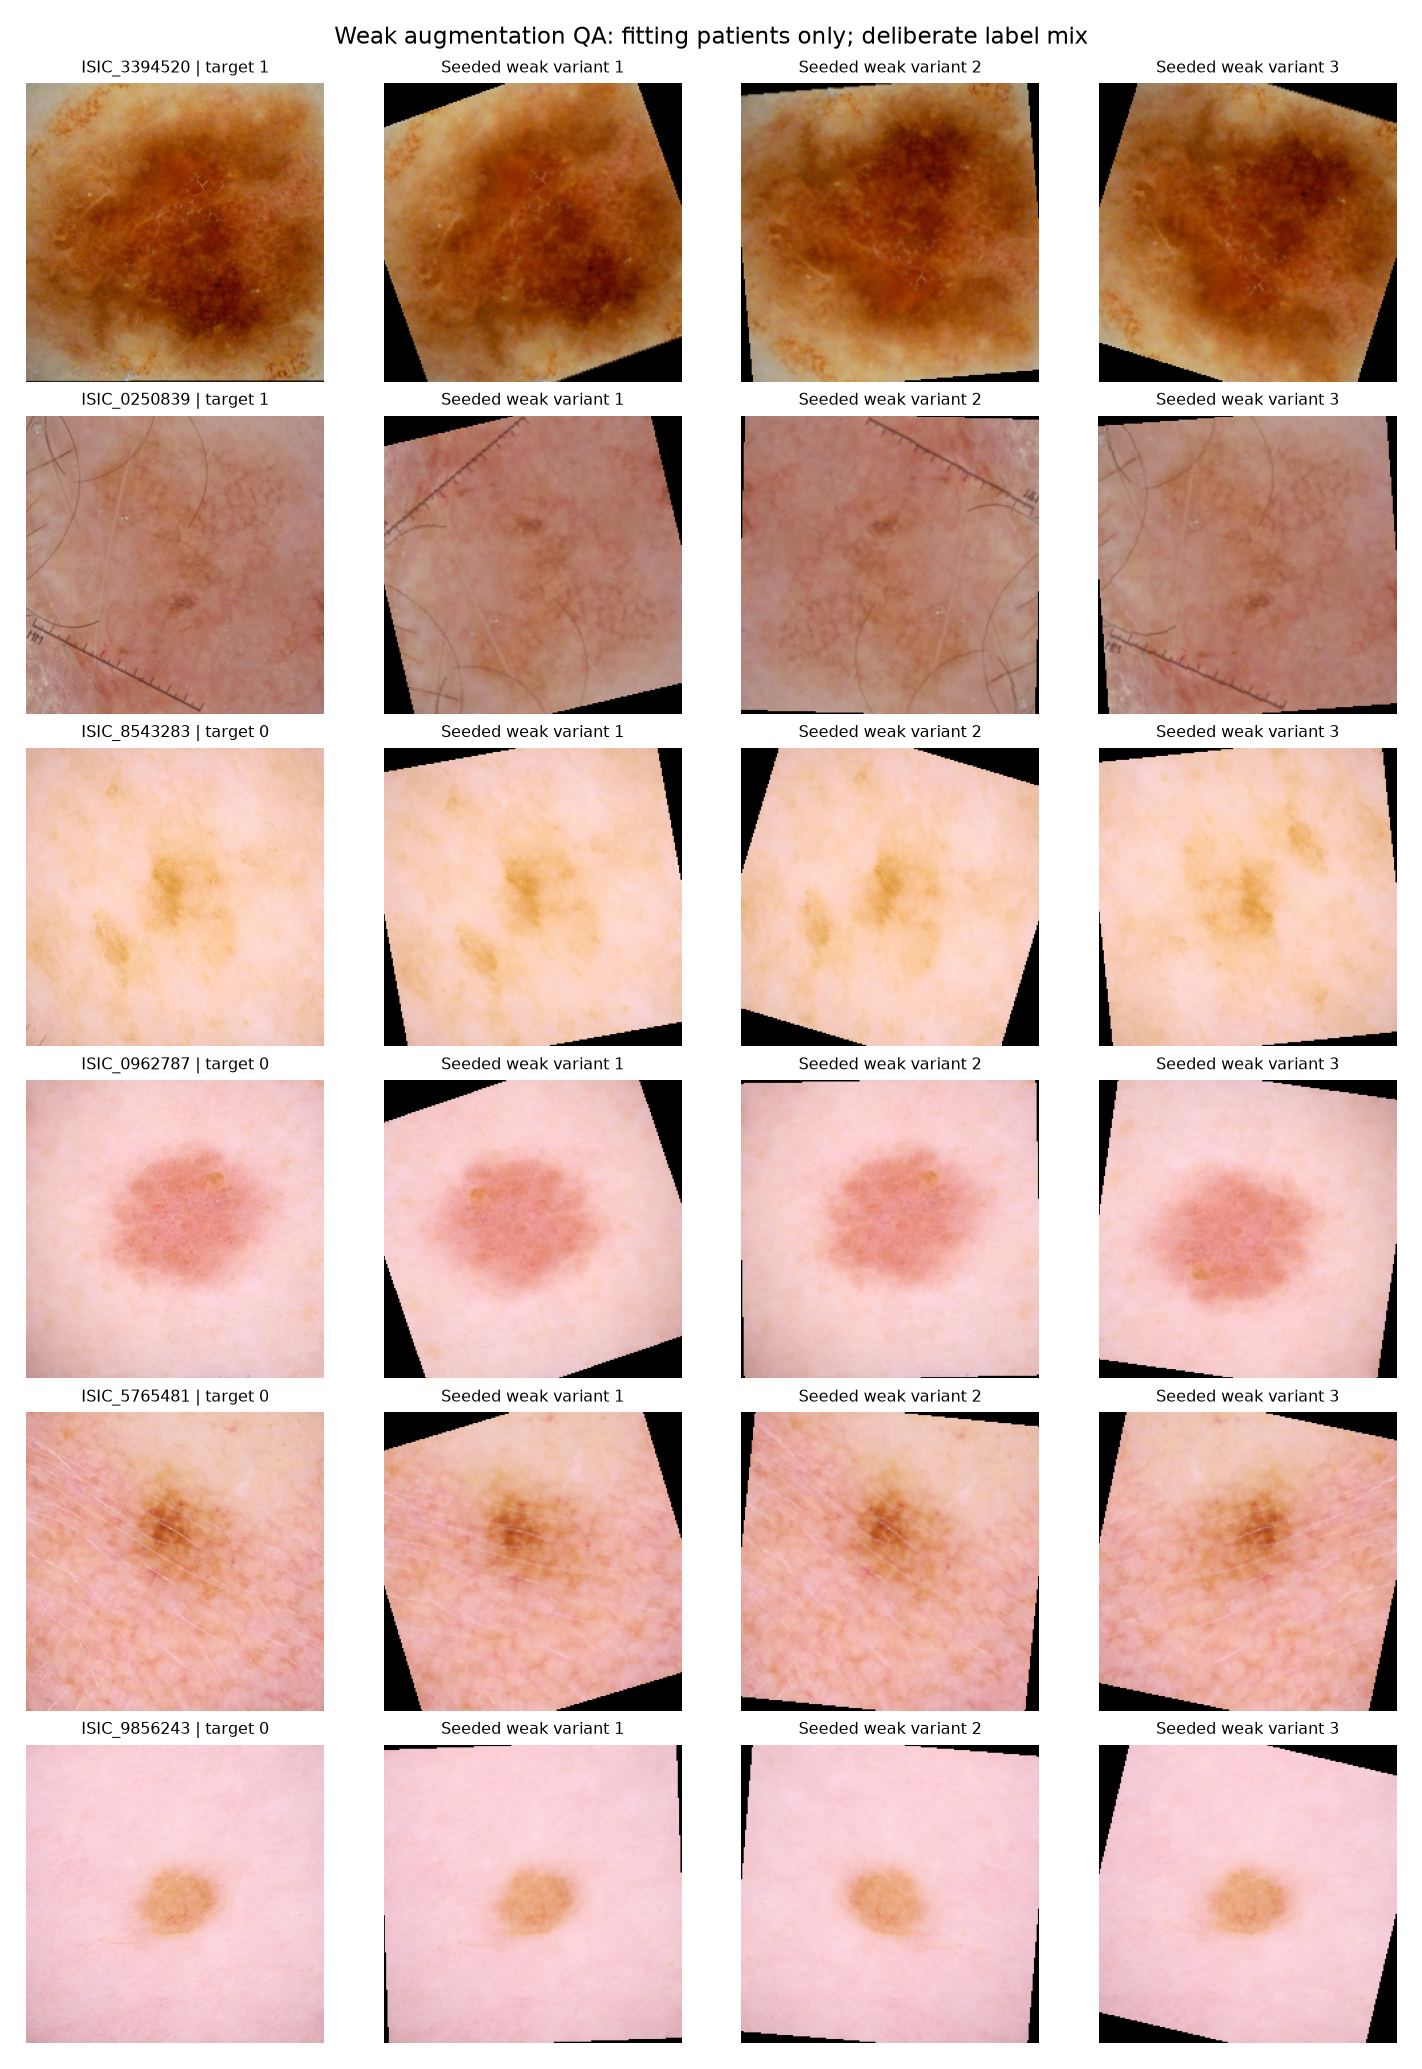

In [4]:
show_saved_figure(PROJECT_ROOT,"results/image_d1_runs/b0_pilot_reporting_v2/figures/weak_augmentation_preview.png")

## Prediction quality and computing cost

**AP** summarises precision (how many flagged images are malignant) as recall
(how many malignant images are found) changes across score cutoffs. Higher is
better; the malignant-image fraction is a useful chance-ranking reference.
**ROC-AUC** measures ranking across both classes; higher is better and 0.5 is
chance ranking. AP deserves attention because malignant images are rare.
**Log loss** penalises confident wrong scores; **Brier score** averages squared
score errors. Lower is better for both, but a low loss alone can hide poor
melanoma detection in an imbalanced dataset.

These outputs are prediction **scores**, not verified clinical probabilities.
Class weighting gives malignant fitting examples more influence and can change
the score scale. The constant fitting-prevalence row is a simple baseline.

All four recipes ran six epochs, including one classifier-only warmup before
adapting the whole network. The fixed learning-rate schedule spans 30 epochs;
that schedule is distinct from the executed six-epoch budget and selected epoch.
Exact AP ties retain the earlier checkpoint. The resource table reports measured
epoch time and allocated GPU memory, excluding setup/download overhead.


In [5]:
metrics = metric_table(predictions, threshold=.5, epochs=epochs)
metrics.to_csv(tables_dir / "exploratory_metrics_threshold_0_5.csv", index=False)
probability_columns = ["pipeline_id", "selected_epoch", "roc_auc", "average_precision", "log_loss", "brier"]
display(metrics[probability_columns].style.format({key: "{:.4f}" for key in probability_columns[2:]}))
baseline = probability_metrics(pilot["validation"].target,
    np.full(len(pilot["validation"]), pilot["fitting"].target.mean()))
display(pd.DataFrame([{"reference": "Constant fitting-prevalence score", **baseline}]))
resources = history.groupby("pipeline_id").agg(completed_epochs=("epoch", "max"),
    measured_training_minutes=("epoch_seconds", lambda values: values.sum() / 60),
    mean_epoch_seconds=("epoch_seconds", "mean"),
    peak_allocated_GiB=("peak_memory_bytes", lambda values: values.max() / 2**30),
    microbatch=("microbatch", "min"), skipped_AMP_updates=("skipped_optimizer_updates", "sum"))
resources.to_csv(tables_dir / "measured_resources.csv")
display(resources.style.format({"measured_training_minutes": "{:.2f}",
    "mean_epoch_seconds": "{:.2f}", "peak_allocated_GiB": "{:.2f}"}))


,pipeline_id,selected_epoch,roc_auc,average_precision,log_loss,brier
0,efficientnet_b0/lr3e5_none,5,0.8426,0.1155,0.0774,0.0170
1,efficientnet_b0/lr1e4_none,4,0.8602,0.1119,0.0763,0.0169
2,efficientnet_b0/lr3e5_sqrt,6,0.8663,0.1383,0.0876,0.0210
3,efficientnet_b0/lr1e4_sqrt,6,0.8734,0.1097,0.0793,0.0199


,reference,average_precision,roc_auc,log_loss,brier
0,Constant fitting-prevalence score,0.017993,0.5,0.090159,0.017671


,completed_epochs,measured_training_minutes,mean_epoch_seconds,peak_allocated_GiB,microbatch,skipped_AMP_updates
pipeline_id,,,,,,
efficientnet_b0/lr1e4_none,6,3.29,32.85,2.81,64,7
efficientnet_b0/lr1e4_sqrt,6,3.47,34.69,2.81,64,8
efficientnet_b0/lr3e5_none,6,3.43,34.30,2.81,64,7
efficientnet_b0/lr3e5_sqrt,6,3.31,33.06,2.81,64,8


## Learning over epochs

**Read the first figure:** the horizontal axis is completed epoch; each line is
one recipe. The upper panels show AP and ROC-AUC (higher is better); the lower
panels show validation log loss and Brier (lower is better). Horizontal guides
mark prevalence for AP and 0.5 for ROC-AUC. Hollow rings mark the epoch chosen
by AP in every panel, rather than each panel's separate optimum. The dotted
vertical line separates classifier warmup from whole-network fine-tuning.

**Read the second figure:** epoch is horizontal and fitting binary cross-entropy
(BCE), the training objective, is vertical. Falling loss shows a closer fit to
training labels; improvement should also appear on validation. Panels separate
weighted and unweighted objectives because their magnitudes are not comparable.
A late AP peak motivates further checking, not proof that longer training helps.


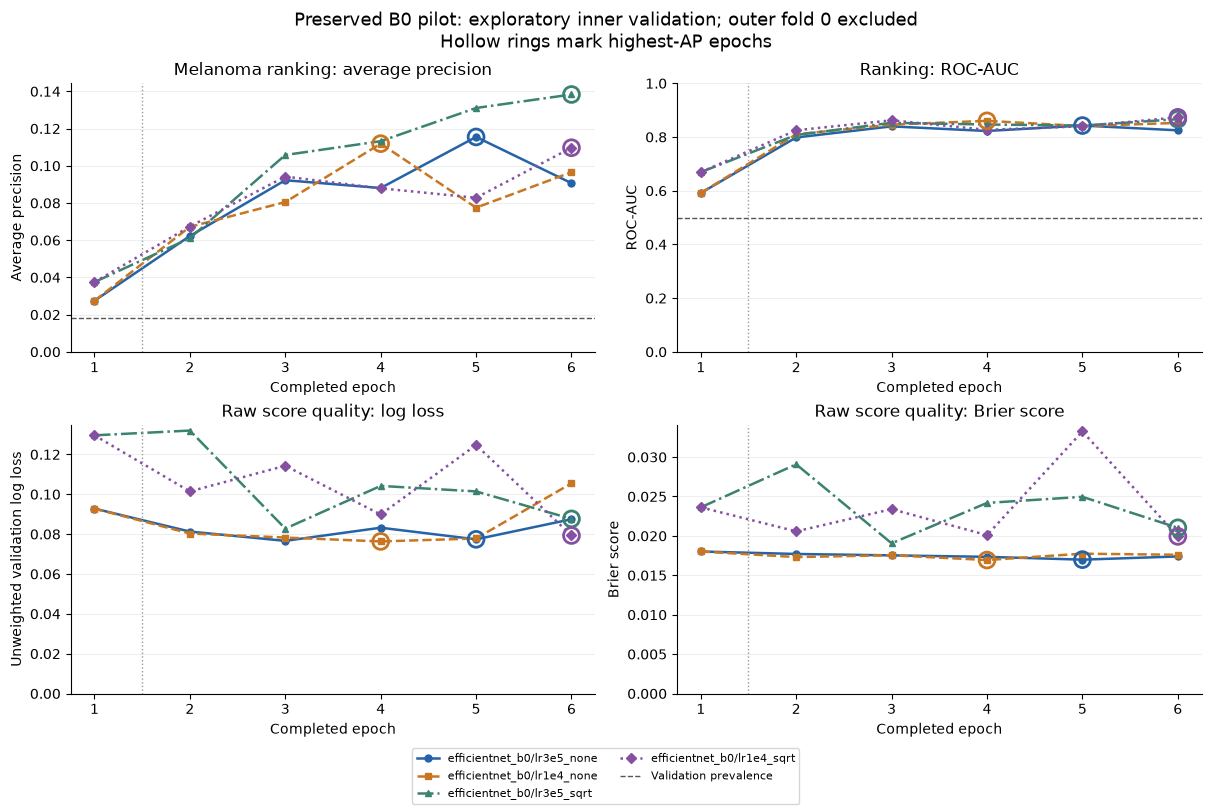

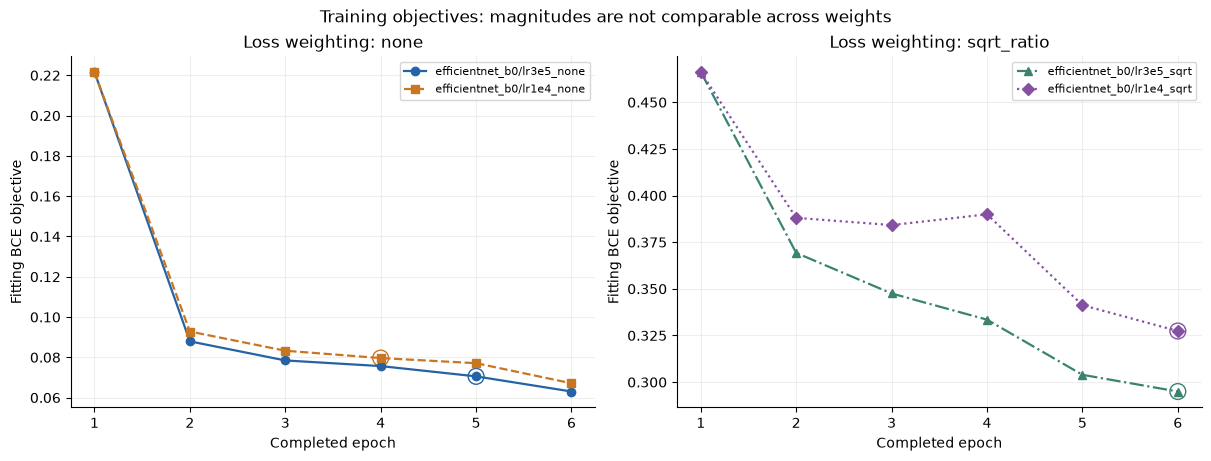

In [6]:
learning = plot_learning_curves(history, pilot["validation"].target.mean(),
    "Preserved B0 pilot: exploratory inner validation; outer fold 0 excluded")
save_figure(learning, figures_dir / "learning_curves.png")
plt.show()
losses = plot_training_losses(history)
save_figure(losses, figures_dir / "training_loss_by_weight.png")
plt.show()


## ROC and precision–recall curves

**Read the curves:** each line is a recipe's selected checkpoint on the same
1,834 images from 113 patients. Moving along a line changes the score cutoff.
The left panel plots false-positive rate (benign images flagged) horizontally
against recall/sensitivity (malignant images found) vertically; curves closer
to the upper left rank better than the chance diagonal. The right panel plots
recall horizontally against precision vertically. Higher precision at the same
recall is better; the horizontal guide shows malignant-image prevalence.

AP summarises precision–recall ranking; it is not the trapezoidal area under
the plotted steps. Neither curve selects a practical cutoff. These patients
also helped select the checkpoints, so the comparison remains exploratory.


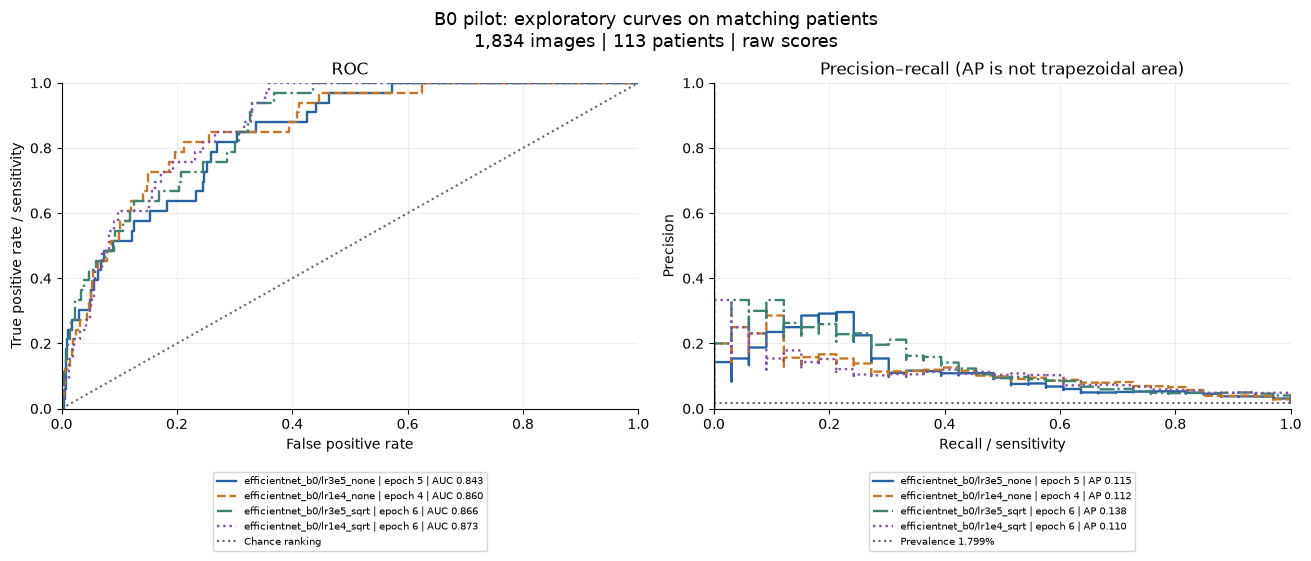

In [7]:
curves = plot_roc_precision_recall(predictions, epochs=epochs,
    title="B0 pilot: exploratory curves on matching patients")
save_figure(curves, figures_dir / "roc_precision_recall.png")
plt.show()
for identity, frame in predictions.items():
    for name, table in curve_tables(frame.target, frame.base_probability).items():
        if isinstance(table, pd.DataFrame):
            table.to_csv(tables_dir / f"{identity.replace('/', '__')}_{name}.csv", index=False)


## Classification at the fixed score cutoff 0.5

An image is flagged when `base_probability >= 0.5`; this stored column contains
an uncalibrated score despite its name. The cutoff is declared, not tuned here.
Recall/sensitivity measures malignant images found; specificity measures benign
images correctly left unflagged. Precision measures malignancy among flags;
F1 balances precision and recall. Undefined ratios remain missing.

**Read each confusion matrix:** rows are true class and columns predicted class.
The diagonal contains correct decisions. Bottom left contains missed melanoma
images (false negatives); top right contains benign images flagged (false
positives). Cell text gives counts and percentages within each true-class row;
darker blue means a larger row fraction. Compare both errors rather than the
many correct benign images. A strong ranking score does not guarantee useful
recall at this cutoff. The later 80%-recall scenario requires training-only OOF
scores; outer evaluation labels must not choose a threshold.


,pipeline_id,selected_epoch,threshold,score_type,TP,FP,TN,FN,precision,recall,sensitivity,specificity,f1,n_images,n_patients
0,efficientnet_b0/lr3e5_none,5,0.500000,raw_base_probability,0,1,1800,33,0.0000,0.0000,0.0000,0.9994,0.0000,1834,113
1,efficientnet_b0/lr1e4_none,4,0.500000,raw_base_probability,0,0,1801,33,Undefined,0.0000,0.0000,1.0000,0.0000,1834,113
2,efficientnet_b0/lr3e5_sqrt,6,0.500000,raw_base_probability,4,14,1787,29,0.2222,0.1212,0.1212,0.9922,0.1569,1834,113
3,efficientnet_b0/lr1e4_sqrt,6,0.500000,raw_base_probability,3,14,1787,30,0.1765,0.0909,0.0909,0.9922,0.1200,1834,113


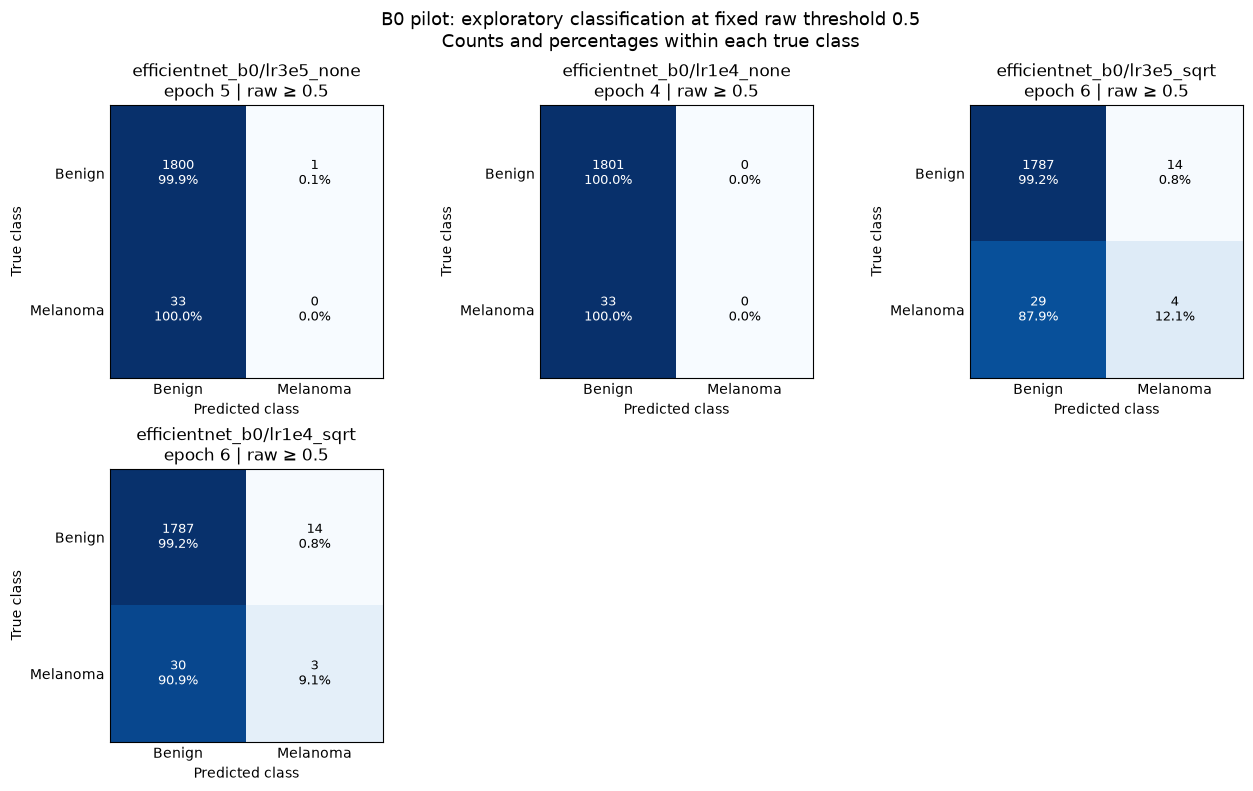

At threshold 0.5 the preferred weighted recipe detects 4 of 33 melanoma images (recall 12.1%) and flags 14 benign images. Ranking performance alone does not establish useful classification at this cutoff.

In [8]:
classification_columns = ["pipeline_id", "selected_epoch", "threshold", "score_type", "TP", "FP", "TN", "FN",
    "precision", "recall", "sensitivity", "specificity", "f1", "n_images", "n_patients"]
display(metrics[classification_columns].style.format({name: "{:.4f}" for name in
    ["precision", "recall", "sensitivity", "specificity", "f1"]}, na_rep="Undefined"))
confusion = plot_confusion_matrices(predictions, epochs=epochs, threshold=.5,
    title="B0 pilot: exploratory classification at fixed raw threshold 0.5")
save_figure(confusion, figures_dir / "confusion_threshold_0_5.png")
plt.show()
display(Markdown("At threshold 0.5 the preferred weighted recipe detects 4 of 33 melanoma images "
    "(recall 12.1%) and flags 14 benign images. Ranking performance alone does not establish "
    "useful classification at this cutoff."))


## Descriptive reliability of the scores

**Read the reliability panels:** each panel is a recipe. Similar scores are
grouped into equal-count bins; horizontal position is the bin's mean score and
vertical position is its observed melanoma fraction. The diagonal means score
and frequency agree. Points below it indicate scores exceeding the observed
frequency; points above it indicate the reverse. The shared axes cover the
observed bin means, so check their range before comparing other plots.

The table gives each bin's image, patient and malignant-image counts. Few
malignant images and repeated images from a patient make the estimates noisy.
This describes reliability; it does not fit a calibrator (a score-to-probability
mapping) or establish accurate clinical probabilities.


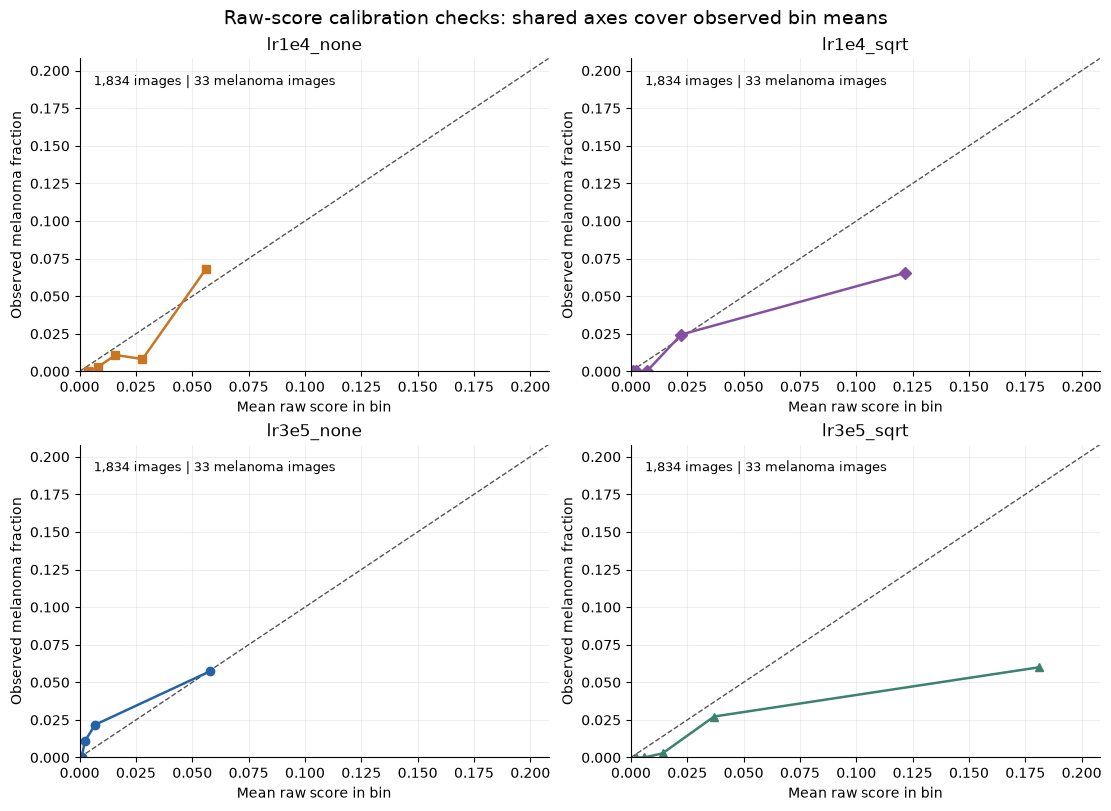

,recipe_id,bin,n_images,n_malignant_images,n_patients,mean_probability,observed_rate
0,lr1e4_none,1,367,0,37,0.0039,0.0000
1,lr1e4_none,2,367,1,68,0.0080,0.0027
2,lr1e4_none,3,366,4,78,0.0159,0.0109
3,lr1e4_none,4,367,3,87,0.0279,0.0082
4,lr1e4_none,5,367,25,77,0.0561,0.0681
5,lr1e4_sqrt,1,367,0,36,0.0009,0.0000
6,lr1e4_sqrt,2,367,0,53,0.0021,0.0000
7,lr1e4_sqrt,3,366,0,82,0.0070,0.0000
8,lr1e4_sqrt,4,367,9,86,0.0224,0.0245
9,lr1e4_sqrt,5,367,24,81,0.1214,0.0654


In [9]:
reliability = plot_reliability_checks(run_dir)
save_figure(reliability, figures_dir / "raw_reliability.png")
plt.show()
bins = pd.concat([pd.read_csv(path).assign(recipe_id=path.parent.name)
    for path in sorted((run_dir / "recipes").glob("*/reliability.csv"))], ignore_index=True)
bins.to_csv(tables_dir / "raw_reliability_support.csv", index=False)
display(bins[["recipe_id", "bin", "n_images", "n_malignant_images", "n_patients",
    "mean_probability", "observed_rate"]].style.format(
    {"mean_probability": "{:.4f}", "observed_rate": "{:.4f}"}))


## Interpretation and next steps

The preferred B0 recipe has AP 0.1383 at epoch 6. Its late peak supports checking
duration on further patient splits; it does not establish an optimal duration
or make B0 the final architecture. [Notebook 10](10_image_architecture_comparison.ipynb)
compares other families. [Notebook 11](11_image_augmentation.ipynb) reports the
later augmentation quality gate; [notebook 12](12_image_lighting.ipynb) explains
why lighting correction was deferred. [Notebook 13](13_image_uncertainty.ipynb)
contains current inference diagnostics.

Longer confirmation across three inner folds, calibration, full outer evaluation
and any fusion remain later work. The reserved test stays outside development.


In [10]:
display(Markdown("**Historical AP selection:** the recorded recommendation/epoch remains unchanged; current ROC summaries do not reselect an image procedure."))
display(Markdown(summary["recommendation"]))
display(pd.DataFrame([summary["runtime_estimates"]]))
(report_dir / "reporting_receipt.json").write_text(json.dumps({
    "reporting_version": 2, "historical_run_id": "b0_pilot_v1", "verified": pilot["verification"],
    "threshold": .5, "threshold_tuned": False, "calibration_fitted": False,
    "outer_predictions_generated": False,
    "status": summary["status"],
    "reporting_source_sha256": {relative: sha256(PROJECT_ROOT / relative) for relative in [
        "src/melanoma_detection/image_evaluation.py", "src/melanoma_detection/image_reporting.py",
        "scripts/build_image_notebook.py"]},
    "summary_sha256": sha256(run_dir / "summary.json"),
    "prediction_csv_sha256": {str(path.relative_to(PROJECT_ROOT)): sha256(path)
        for path in sorted((run_dir / "recipes").glob("*/inner_validation_predictions.csv"))},
    "figures": sorted(path.name for path in figures_dir.glob("*.png"))}, indent=2), encoding="utf-8")
print("New reports:", report_dir)
print("Original pilot artifacts: unchanged | outer evaluation: not performed | calibration: not fitted")


**Historical AP selection:** the recorded recommendation/epoch remains unchanged; current ROC summaries do not reselect an image procedure.

Best inner AP is near the pilot cap; extend all four candidates on inner patients to a 30-epoch cap before stronger claims.

,measured_b0_mean_epoch_seconds,four_30_epoch_b0_fit_hours_same_split,future_nested_maximum_logical_fits,future_nested_maximum_unequal_training_epochs,optional_swin_added_fits,optional_stability_added_fits,future_hours,qualification
0,33.726012,1.1242,180,4380,35,10,None,B0 pilot timing cannot estimate unequal unmeas...


New reports: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\results\metadata_nn_tuning\v2\report_verification\image_reports\original\09_image_b0_pilot
Original pilot artifacts: unchanged | outer evaluation: not performed | calibration: not fitted


## Limitations

- One inner patient split and six epochs show early behaviour, not final performance.
- Recipe and epoch choices reuse these validation labels, which can make results optimistic.
- Class-weighted scores are uncalibrated; 0.5 is a reporting cutoff with potentially low recall.
- Weighted/unweighted fitting losses have different scales and cannot rank recipes against each other.
- A finite image preview cannot certify every lesion. At this historical pilot's completion, full outer evaluation was pending; the completed five-fold results now appear in [notebook 14](14_image_nested_evaluation.ipynb) and [clean notebook 09](../Subset_dedup/09_image_modelling.ipynb). The reserved test remains unevaluated.


## Summary

The saved six-epoch experiment provides a verified B0 reference. Read AP alongside
the fixed-cutoff errors, score reliability and computing cost. The observations
below guide further experiments; they do not select the final architecture.


In [11]:
display(Markdown("**Historical AP selection:** the recorded recommendation/epoch remains unchanged; current ROC summaries do not reselect an image procedure."))
preferred = summary.get("selected_recipe")
if preferred is not None:
    selected = pilot["records"].loc[pilot["records"].recipe_id.eq(preferred)]
    display(selected[["pipeline_id", "best_epoch", "roc_auc", "average_precision", "log_loss", "brier"]])
display(Markdown(summary["recommendation"]))
print("Completed four six-epoch trials; no final architecture chosen and no outer/test evaluation performed.")


**Historical AP selection:** the recorded recommendation/epoch remains unchanged; current ROC summaries do not reselect an image procedure.

,pipeline_id,best_epoch,roc_auc,average_precision,log_loss,brier
2,efficientnet_b0/lr3e5_sqrt,6,0.866337,0.138318,0.087642,0.021026


Best inner AP is near the pilot cap; extend all four candidates on inner patients to a 30-epoch cap before stronger claims.

Completed four six-epoch trials; no final architecture chosen and no outer/test evaluation performed.
